# Diverging Bar Chart (Revenue Growth and Loss Drivers)

## Исходные данные для построения

- датафрейм

In [3]:
revenue_matrix = pd.read_csv('revenue_matrix.csv')
revenue_matrix

,From,To,Revenue,Revenue_Change,Customers,Revenue_M,Revenue_Change_M,Revenue_Driver
0,Active,Active,7323667.0,317150.0,4211,7.323667,0.317150,Expansion
1,Active,At Risk,2864477.0,-164591.0,2113,2.864477,-0.164591,Contraction
2,Active,Loyal,1808909.0,668920.0,479,1.808909,0.668920,Expansion
3,At Risk,Active,742862.0,144261.0,436,0.742862,0.144261,Reactivation
4,At Risk,At Risk,5069889.0,-883654.0,4202,5.069889,-0.883654,Contraction
5,At Risk,Churn,0.0,-1510818.0,1446,0.000000,-1.510818,Churn
6,At Risk,Loyal,394206.0,91892.0,92,0.394206,0.091892,Reactivation
7,Churn,Active,116080.0,116080.0,105,0.116080,0.116080,Reactivation
8,Churn,Churn,0.0,0.0,2353,0.000000,0.000000,Churn
9,Churn,Loyal,2856.0,2856.0,1,0.002856,0.002856,Reactivation


## Код для построения

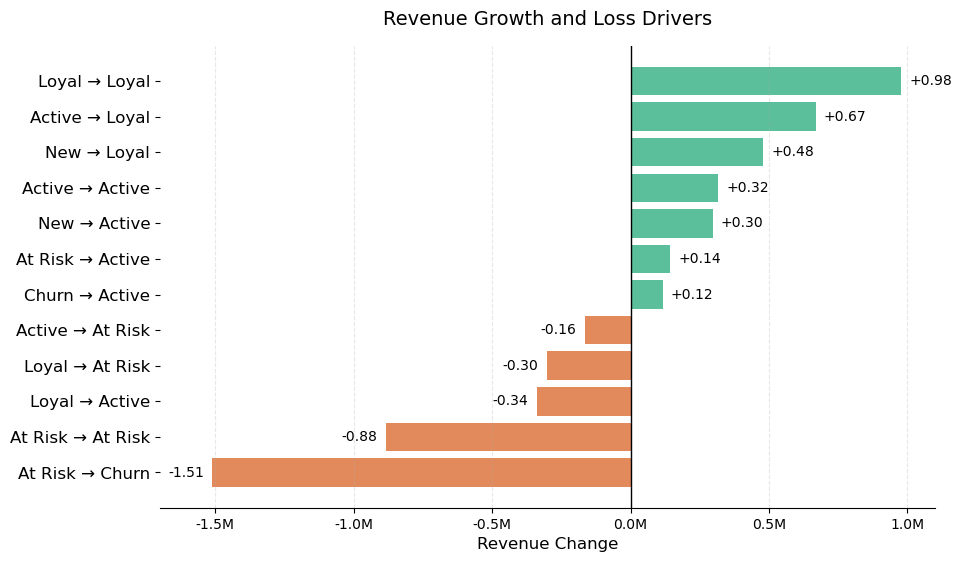

In [7]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# =====================================================
# LOAD DATA
# =====================================================

revenue_matrix = pd.read_csv('revenue_matrix.csv')

# =====================================================
# The meaning of colors
# =====================================================

POSITIVE_LIGHT = '#5ABF9A'
NEGATIVE_LIGHT = '#E28A5B'

# =====================================================
# PREPARE DATA
# =====================================================

# .assign - добавляет новые столбцы к таблице (DataFrame) и возвращает новую копию, не меняя при этом исходный объект
# .nlargest - Возвращает n строк с самыми большими значениями в указанном столбце.
plot_df = (
    revenue_matrix
    .assign(
        Transition=lambda x: x['From'] + ' → ' + x['To']
    )
    .assign(
        Impact=lambda x: x['Revenue_Change_M'].abs()
    )
    .nlargest(12, 'Impact')
    .sort_values('Revenue_Change_M')
)

# АЛЬТЕРНАТИВА

# Название перехода
# plot_df['Transition'] = plot_df['From'] + ' → ' + plot_df['To']

# Сортировка от самых больших потерь к самому большому росту
# plot_df = plot_df.sort_values('Revenue_Change_M')

# =====================================================
# PLOT
# =====================================================

# Цвета
colors = plot_df['Revenue_Change_M'].apply(
    lambda x: NEGATIVE_LIGHT if x < 0 else POSITIVE_LIGHT     #D55E00   #d62728 #ff4040 #009E73
)

# Размер фигуры зависит от числа строк
fig_height = max(6, len(plot_df) * 0.45)


fig, ax = plt.subplots(figsize=(10, fig_height))

bars = ax.barh(
    plot_df['Transition'],
    plot_df['Revenue_Change_M'],
    color=colors
)

# Вертикальная линия нуля
ax.axvline(
    0,
    color='black',
    linewidth=1
)

# Подписи значений
for bar in bars:

    width = bar.get_width()

    if width >= 0:
        ax.text(
            width + 0.03,
            bar.get_y() + bar.get_height()/2,
            f'+{width:.2f}',
            va='center',
            ha='left',
            fontsize=10
        )
    else:
        ax.text(
            width - 0.03,
            bar.get_y() + bar.get_height()/2,
            f'{width:.2f}',
            va='center',
            ha='right',
            fontsize=10
        )

# =====================================================
# ОФОРМЛЕНИЕ
# =====================================================

# Легкая сетка
ax.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

# Наименования осей
ax.set_title(
    'Revenue Growth and Loss Drivers',
    fontsize=14,
#    weight='bold',
    pad=15
)
ax.set_xlabel('Revenue Change', fontsize=12)
ax.set_ylabel('')


# Границы оси Х 
ax.set_xlim(-1.7, 1.1)
ax.tick_params(axis='y', labelsize=12)

# Убрать рамку графика
sns.despine(left=True)

def millions_formatter(x, pos):
    """Форматирует значения оси Y в миллионах с одним знаком"""
    return f'{x}M'

# Применяем форматтер к оси Y
ax.xaxis.set_major_formatter(FuncFormatter(millions_formatter))

#plt.savefig('revenue_drivers.png', dpi=300, bbox_inches='tight')

plt.show()

In [6]:
plot_df

,From,To,Revenue,Revenue_Change,Customers,Revenue_M,Revenue_Change_M,Revenue_Driver,Transition,Impact
5,At Risk,Churn,0.0,-1510818.0,1446,0.000000,-1.510818,Churn,At Risk → Churn,1.510818
4,At Risk,At Risk,5069889.0,-883654.0,4202,5.069889,-0.883654,Contraction,At Risk → At Risk,0.883654
10,Loyal,Active,576597.0,-338914.0,242,0.576597,-0.338914,Contraction,Loyal → Active,0.338914
11,Loyal,At Risk,1101541.0,-302678.0,307,1.101541,-0.302678,Contraction,Loyal → At Risk,0.302678
1,Active,At Risk,2864477.0,-164591.0,2113,2.864477,-0.164591,Contraction,Active → At Risk,0.164591
7,Churn,Active,116080.0,116080.0,105,0.116080,0.116080,Reactivation,Churn → Active,0.116080
3,At Risk,Active,742862.0,144261.0,436,0.742862,0.144261,Reactivation,At Risk → Active,0.144261
13,New,Active,3051581.0,296727.0,2179,3.051581,0.296727,Expansion,New → Active,0.296727
0,Active,Active,7323667.0,317150.0,4211,7.323667,0.317150,Expansion,Active → Active,0.317150
14,New,Loyal,926572.0,479613.0,181,0.926572,0.479613,Expansion,New → Loyal,0.479613
